In [1]:
from keras.applications.vgg16 import VGG16

In [2]:

import pandas as pd
!pip install -q kaggle
from google.colab import files

!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600  ~/.kaggle/kaggle.json
!kaggle datasets download -d samuelcortinhas/cats-and-dogs-image-classification


 98% 63.0M/64.4M [00:00<00:00, 207MB/s]
100% 64.4M/64.4M [00:00<00:00, 193MB/s]


In [3]:
!unzip /content/cats-and-dogs-image-classification.zip

Archive:  /content/cats-and-dogs-image-classification.zip
  inflating: test/cats/cat_1.jpg     
  inflating: test/cats/cat_106.jpg   
  inflating: test/cats/cat_109.jpg   
  inflating: test/cats/cat_113.jpg   
  inflating: test/cats/cat_114.jpg   
  inflating: test/cats/cat_116.jpg   
  inflating: test/cats/cat_118.jpg   
  inflating: test/cats/cat_119.jpg   
  inflating: test/cats/cat_124.jpg   
  inflating: test/cats/cat_140.jpg   
  inflating: test/cats/cat_147.jpg   
  inflating: test/cats/cat_156.jpg   
  inflating: test/cats/cat_158.jpg   
  inflating: test/cats/cat_162.jpg   
  inflating: test/cats/cat_18.jpg    
  inflating: test/cats/cat_190.jpg   
  inflating: test/cats/cat_203.jpg   
  inflating: test/cats/cat_223.jpg   
  inflating: test/cats/cat_234.jpg   
  inflating: test/cats/cat_244.jpg   
  inflating: test/cats/cat_251.jpg   
  inflating: test/cats/cat_255.jpg   
  inflating: test/cats/cat_268.jpg   
  inflating: test/cats/cat_279.jpg   
  inflating: test/cats/cat_281

In [4]:
import glob
import cv2
import os
# train

train_images = []
train_labels = []

for path in glob.glob("/content/train/*"):
  label = path.split("/")[-1]
  print(label)

  for image_path in glob.glob(os.path.join(path , "*.jpg")):
    #print(image_path)
    img = cv2.imread(image_path , cv2.IMREAD_COLOR)
    img = cv2.resize(img , (224,224))
    img = cv2.cvtColor(img , cv2.COLOR_RGB2BGR)
    train_images.append(img)
    train_labels.append(label)


dogs
cats


In [5]:
# test
test_images = []
test_labels = []

for path in glob.glob("/content/test/*"):
  label = path.split("/")[-1]
  print(label)

  for image_path in glob.glob(os.path.join(path , "*.jpg")):
    #print(image_path)
    img = cv2.imread(image_path , cv2.IMREAD_COLOR)
    img = cv2.resize(img , (224,224))
    img = cv2.cvtColor(img , cv2.COLOR_RGB2BGR)
    test_images.append(img)
    test_labels.append(label)



dogs
cats


In [6]:
import numpy as np
test_images = np.array(test_images)
test_labels = np.array(test_labels)


train_images = np.array(train_images)
train_labels = np.array(train_labels)

In [7]:
len(train_images) , len(train_labels)

(557, 557)

In [8]:
# encoding labels
from sklearn import preprocessing
le = preprocessing.LabelEncoder()
le.fit(test_labels)
test_label_encoded = le.transform(test_labels)

le.fit(train_labels)
train_label_encoded = le.transform(train_labels)

train_label_encoded[0] , train_labels[0]

(1, 'dogs')

In [9]:
x_train , y_train , x_test , y_test = train_images , train_label_encoded , test_images , test_label_encoded


In [10]:
x_train.shape , train_images.shape

((557, 224, 224, 3), (557, 224, 224, 3))

# ilk model vgg

In [12]:
vgg_model = VGG16(weights="imagenet" , include_top=False , input_shape=(224,224,3))

58889256/58889256 [==============================] - 0s 0us/step


In [13]:
vgg_model.summary() # 14714688 trainable param

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [14]:
for layer in vgg_model.layers:
  layer.trainable= False

vgg_model.summary() # zero trainable parametres

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [15]:
extractor = vgg_model.predict(x_train)
feature = extractor.reshape(extractor.shape[0],-1)

18/18 [==============================] - 291s 16s/step


In [24]:
extractor.shape

(557, 7, 7, 512)

In [23]:
feature = extractor.reshape(extractor.shape[0],-1)
feature.shape

(557, 25088)

In [25]:
from sklearn import svm

# kernel = linear , polynomial , radial basis function(RBF) , sigmoid
classifier = svm.SVC(kernel="linear" , gamma = "auto" , C=2)
classifier.fit(feature , y_train)

SVC(C=2, gamma='auto', kernel='linear')

In [27]:
x_test_extract = vgg_model.predict(x_test)


5/5 [==============================] - 83s 15s/step


In [28]:
x_test_feature = x_test_extract.reshape(x_test_extract.shape[0],-1)

In [29]:
classifier_prediction = classifier.predict(x_test_feature)

In [30]:
classifier_prediction = le.inverse_transform(classifier_prediction)

In [31]:

from sklearn import metrics
print ("Accuracy = ", metrics.accuracy_score(test_labels, classifier_prediction))



Accuracy =  0.8785714285714286


<Axes: >

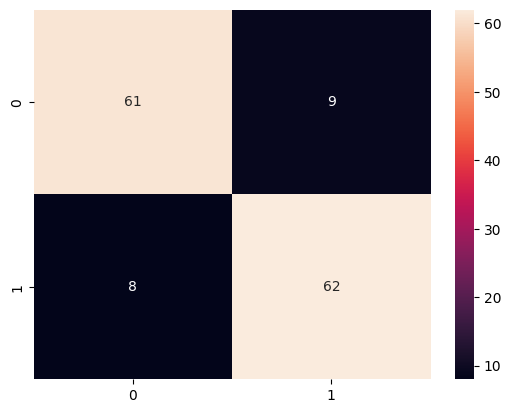

In [32]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(test_labels, classifier_prediction)
#print(cm)
sns.heatmap(cm, annot=True)
